# A minimal PRISM example

## Code structure

```text
prism/
├── prism/                              # Installable PRISM package; the method
│   ├── nn/                             # PRISM model, encoders, tokenizers, decoders
│   │   ├── model.py                    # PrismModel: encoder + mask + parameter heads
│   │   ├── embedding.py                # Generic transformer observation encoder
│   │   ├── compartment_tokenizer.py    # Generic component and parameter tokens
│   │   ├── autoregressive_base.py      # Shared causal decoding and mask sampling
│   │   └── diffusion.py                # Shared diffusion transformer and training loss
│   ├── simulators/                     # Simulator interface and mask priors
│   ├── train/                          # Builders, datasets, training, validation, checkpoints
│   ├── inference/                      # Batched sampling, correctors, KSD, precision
│   ├── config/                         # Configuration schemas, migration, legacy names
│   ├── utils/                          # Generic numerical utilities
│   ├── symbolic/                       # Symbolic application
│   │   ├── simulators/                 # Functions, additive models, and noise
│   │   └── paper/                      # Frozen Figure 4b network, specs and mask table
│   └── dmri/                           # Diffusion MRI application
│       ├── simulators/                 # Compartments and acquisition schemes
│       ├── nn/                         # dMRI encoders, tokenizers and model presets
│       └── eval/                       # Volumetric evaluation, data loading, export
├── conf/                               # Hydra model, simulator, and experiment settings
├── experiments/                        # Scientific evaluation workflows
│   ├── symbolic/                       # Simulation efficiency and model-space scaling
│   └── dmri/                           # Calibration and synthetic posterior evaluation
├── examples/                           # Runnable tutorials and a small smoke test
│   ├── symbolic/                       # This notebook and symbolic workflows
│   └── dmri/                           # dMRI simulator, training, and inference examples
├── docs/                               # Guides and generated notebook reading pages
├── tests/                              # Automated checks
├── pyproject.toml                      # Package metadata and dependencies
└── uv.lock                             # Locked dependency versions
```

This notebook calls the simulator and network classes directly, defines a small
training loop, and uses `prism/train/checkpointing.py` for EMA save/restore.
The full configurable training entry point is `prism/train/train_script.py`.
Paper evaluation scripts live in `experiments/`; they are separate from the core package.


## Minimal example

Learn a posterior over **which terms are present** and **their coefficients**:

$$y(x) = m_1 a x + m_2 b x^2 + \epsilon, \qquad
\epsilon \sim \mathcal N(0,\sigma^2).$$

We will simulate data, train a small PRISM model, sample its posterior, and
generate new curves. The network, simulator, losses, and samplers all come from
`prism`; this notebook only connects them. The small training budget illustrates
the workflow, rather than establishing posterior accuracy or reproducing a paper result.

Use the repository's installed Python environment. No downloaded data or
pretrained weights are needed. All random seeds are fixed.

In [1]:
# External libraries: JAX handles arrays and random keys; Flax NNX manages
# network state; Optax supplies optimization; NumPy and Matplotlib display results.
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from flax import nnx

## 1. Generate training examples

`SimplePolynomial` combines a linear term, a quadratic term, and Gaussian noise.
Its mask is `[linear, quadratic, noise]`; the noise bit is always active.
The simulator converts unconstrained parameters to coefficients
$a\in[-2,2]$, $b\in[-1,1]$, and noise scale $\sigma\in[0.05,0.25]$.

For each example, draw $\lambda\sim\operatorname{Beta}(1,1)$, then a mask,
then $\theta\sim\mathcal N(0,I)$, and finally an observed curve.
This prior draws Bernoulli bits with probability $\lambda$ and forces one
randomly chosen function to be active, so the function is never empty.
Thus the final mask is not simply two independent Bernoulli bits.

The symbolic encoder groups **ten consecutive y-values into one token**.
Here every example uses the same ordered 100-point grid, giving shape `(10, 10)`.
Positions are encoded by the network; x-coordinates are not passed as extra features.

A batch of 32 contains 32 different curves, each with 100 observation points.

In [2]:
# SimplePolynomial: prism/symbolic/simulators/__init__.py.
# from_theta: prism/simulators/base.py; evaluate: prism/symbolic/simulators/base.py.
from prism.symbolic.simulators import SimplePolynomial

Simulator = SimplePolynomial
grid = jnp.linspace(-1.0, 1.0, 100)

# create_mask_prior: AdditiveModel in prism/symbolic/simulators/base.py.
# prior.sample: MaskPrior in prism/simulators/mask_prior.py; this model uses
# BetaBernoulliMaskPrior from the same file.
# simulate is a notebook wrapper; JAX vmap batches it and jit compiles it.
prior = Simulator.create_mask_prior(alpha=1.0, beta=1.0)


def simulate(key):
    prior_key, theta_key, noise_key = jax.random.split(key, 3)
    prior_sample = prior.sample(prior_key)
    theta = jax.random.normal(theta_key, (Simulator.theta_dim,))
    mask = prior_sample.model_mask
    simulator = Simulator.from_theta(theta, model_mask=mask)
    y = simulator.evaluate(grid, rng=noise_key)
    return {
        "y": y.reshape(-1, 10),
        "mask": mask,
        "theta": theta,
        "lambda": prior_sample.hyperparameters,
    }


simulate_batch = jax.jit(jax.vmap(simulate))
batch = simulate_batch(jax.random.split(jax.random.PRNGKey(1), 32))
print({name: value.shape for name, value in batch.items()})

{'lambda': (32, 1), 'mask': (32, 3), 'theta': (32, 3), 'y': (32, 10, 10)}


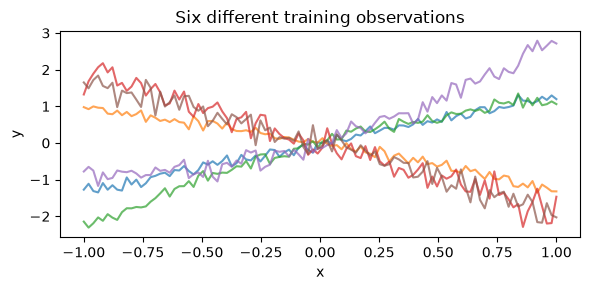

In [3]:
# Notebook visualization: plot six observations from the batch created above.
plt.figure(figsize=(6, 3))
for y in batch["y"][:6]:
    plt.plot(grid, y.reshape(-1), alpha=0.7)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Six different training observations")
plt.tight_layout()
plt.show()

### From a curve to observation tokens

Each colored segment below is one token containing ten adjacent y-values.
The heatmap contains exactly the same 100 values, reshaped into ten rows.
The row order preserves their positions on the shared x-grid.

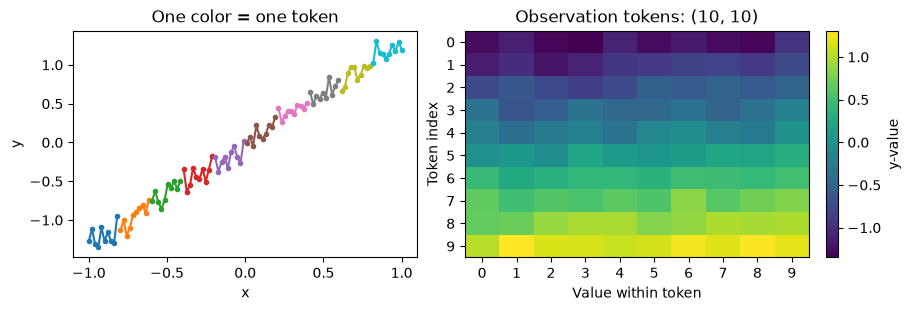

In [4]:
# Notebook visualization: show the same 100 y-values as ten groups of ten.
# This reshapes existing data; it does not call the learned component tokenizer.
token_values = batch["y"][0]
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
colors = plt.get_cmap("tab10")
for index, token in enumerate(token_values):
    axes[0].plot(
        grid[index * 10 : (index + 1) * 10], token, color=colors(index), marker="."
    )
axes[0].set(xlabel="x", ylabel="y", title="One color = one token")
im = axes[1].imshow(token_values, aspect="auto", cmap="viridis")
axes[1].set(
    xlabel="Value within token",
    ylabel="Token index",
    title=f"Observation tokens: {token_values.shape}",
    xticks=range(10),
    yticks=range(10),
)
fig.colorbar(im, ax=axes[1], label="y-value")
plt.show()

## 2. Build a small PRISM model

There are three networks: an **observation encoder**, an **autoregressive mask
decoder**, and a **diffusion parameter decoder**. Together they approximate

$$q(M,\theta\mid y,\lambda)
=q(M\mid y,\lambda)\,q(\theta\mid M,y).$$

The tokenizer represents the simulator's components. We use the existing
symbolic network with one layer per network and width 32. These are tutorial
settings; no experiment configuration is changed.

In [5]:
# Network definitions are in prism/symbolic/paper/: autoregressive.py, embedding.py,
# model.py, simformer.py, and tokenizer.py, matching the imports below.
# Fix input_dim=10 when constructing the observation encoder below.
from functools import partial

# Settings for the mask decoder, conditioned on lambda and observation features.
from prism.symbolic.paper.autoregressive import (
    SymbolicPaperModelSelectionAmortizedPriorConfig,
)
from prism.symbolic.paper.embedding import (
    SymbolicPaperEmbeddingConfig,  # Encoder settings: layers, heads, positional encoding.
    SymbolicPaperEmbeddingTransformer,  # Observation encoder: y tokens -> learned features.
)
from prism.symbolic.paper.model import (
    SymbolicPaperModel,  # Complete network: encoder + mask decoder + parameter decoder.
    SymbolicPaperModelConfigMaskPriorAmortized,  # Combines their settings with lambda conditioning.
)

# Settings for the diffusion decoder that samples theta given a mask and observation.
from prism.symbolic.paper.simformer import SymbolicPaperThetaInferenceConfig

# Converts component identities, mask bits, and theta into tokens for the decoders.
from prism.symbolic.paper.tokenizer import SymbolicPaperTokenizerPP

In [6]:
# SymbolicPaperModel constructs the encoder, tokenizer, and two decoders
# in prism/symbolic/paper/model.py. The small settings below belong to this notebook.
small = dict(num_layers=1, num_heads=2, attn_size=16, widening_factor=2)
network_config = SymbolicPaperModelConfigMaskPriorAmortized(
    simulator=Simulator,
    model_dim=32,
    tokenizer_cls=SymbolicPaperTokenizerPP,
    embedding_cls=partial(SymbolicPaperEmbeddingTransformer, input_dim=10),
    embedding_cfg=SymbolicPaperEmbeddingConfig(**small, use_global_summary_token=True),
    model_selection_cfg=SymbolicPaperModelSelectionAmortizedPriorConfig(
        **small,
        prior_params_embed_dim=32,
        precondition_with_mask_prior=True,
        prior_mask=prior,
    ),
    theta_inference_cfg=SymbolicPaperThetaInferenceConfig(**small, time_embed_dim=32),
)
model = SymbolicPaperModel(network_config, rngs=nnx.Rngs(2))

`Config` classes hold these settings; the resulting modules perform the computations.

| Module on `model` | Role | Settings in this example |
| --- | --- | --- |
| `encoder` | Observation tokens to features and a summary | Input width 10; feature width 32; one transformer layer |
| `tokenizer` | Component identities, masks, and parameters to decoder tokens | Two function components and one noise component; width 32 |
| `model_decoder` | Model probabilities conditioned on the observation and lambda | One layer; two attention heads; 32 prior features |
| `inference_decoder` | Conditional diffusion sampling of parameters | One layer; two attention heads; 32 time features |

The following displays inspect the initialized modules before training.

The main size settings in the configuration have concrete roles:

- `model_dim=32`: each hidden token has 32 features.
- `num_layers=1`: each of the three transformer stacks contains one block.
- `num_heads=2`, `attn_size=16`: two attention heads, each using 16-dimensional queries, keys, and values.
- `widening_factor=2`: the feedforward part of each block expands 32 → 64 → 32.
- `use_global_summary_token=True`: the encoder processes an extra token, then returns its 32-feature summary alongside the ten observation tokens.

The heatmaps below show the initialized embeddings. Posterior probabilities and
predictions appear after training and checkpoint restoration.

### Observation encoder

Inspect one training example with the **initialized, untrained network**.
These heatmaps explain the shapes and flow of data, not learned posterior quality.
`encoder(y)` returns ten feature vectors and one summary vector. Both decoders
receive these observation features.

Each token's ten y-values become 32 features through a projection, positional
encoding, and transformer. Colors show feature values, not probabilities or
attention weights; individual coordinates have no assigned physical meaning.

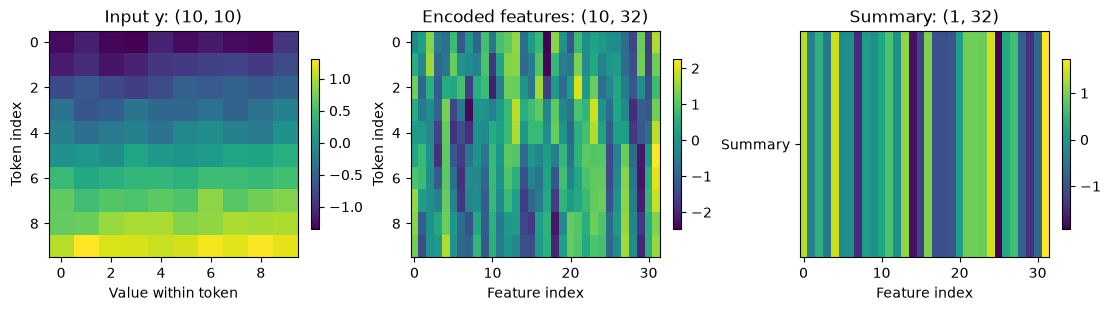

In [7]:
# encoder(y): SymbolicPaperEmbeddingTransformer.__call__ in prism/symbolic/paper/embedding.py.
# The plots display its actual observation features and summary vector.
inspection_observation = {name: values[0] for name, values in batch.items()}
summary, features = model.encoder(inspection_observation["y"], deterministic=True)
assert features.shape == (1, 10, network_config.model_dim)
fig, axes = plt.subplots(1, 3, figsize=(11, 3), layout="constrained")
arrays = [inspection_observation["y"], features[0], summary]
titles = [
    f"Input y: {inspection_observation['y'].shape}",
    f"Encoded features: {features[0].shape}",
    f"Summary: {summary.shape}",
]
for ax, values, title in zip(axes, arrays, titles, strict=True):
    im = ax.imshow(values, aspect="auto", cmap="viridis")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.75)
axes[0].set(xlabel="Value within token", ylabel="Token index")
axes[1].set(xlabel="Feature index", ylabel="Token index")
axes[2].set(xlabel="Feature index", yticks=[0], yticklabels=["Summary"])
plt.show()

### Mask decoder: inputs and embeddings

These four panels collect the mask decoder's inputs for **the same training
example and initialized network**:

1. Component identities distinguish the linear, quadratic, and noise components.
2. The existing tokenizer combines them with start/end information and shifted
   mask-bit embeddings to build the decoder input tokens.
3. Observation features supply the keys and values for cross-attention in each layer.
4. The lambda embedding and observation summary form the per-layer context.
   They are drawn as two rows, but concatenated into one 64-feature vector.

The known training mask is used only to inspect token construction. The decoder
uses shifted inputs and causal attention; the fourth token row's output is
discarded. Colors show embedding values, not probabilities. At inference time,
the generating mask is unknown and is not passed to the network.

In [8]:
# Component and mask embeddings: prism/symbolic/paper/tokenizer.py.
# This follows BinaryAutoregressiveDecoder._encode_model_mask in
# prism/symbolic/paper/autoregressive.py, using the existing tokenizer methods.
tokenizer = model.tokenizer
mask_for_display = inspection_observation["mask"]
mask_component_tokens = tokenizer.encode(model_mask=jnp.ones_like(mask_for_display))
mask_input_tokens = tokenizer.embed_model_mask(mask_component_tokens, mask_for_display)

# Lambda embedding and context: prism/symbolic/paper/autoregressive.py.
# features and summary are the encoder outputs computed directly above.
lambda_embedding = model.model_decoder.mask_prior_embed(
    inspection_observation["lambda"]
)
context_rows = jnp.stack([lambda_embedding, summary[0]])
assert mask_input_tokens.shape == (4, network_config.model_dim)
assert context_rows.size == model.model_decoder.total_context_dim
print("Training example mask:", np.asarray(mask_for_display, dtype=int))
print("Lambda:", float(inspection_observation["lambda"][0]))

Training example mask: [1 0 1]
Lambda: 0.04375943914055824


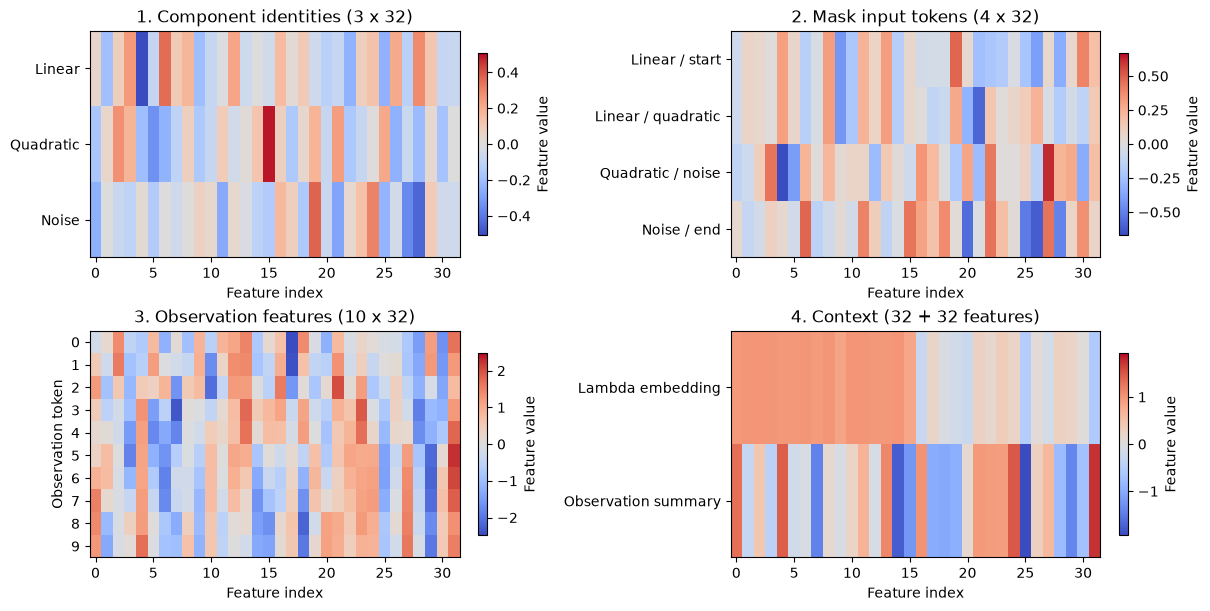

In [9]:
# Notebook visualization: collect the actual mask-decoder inputs in one figure.
fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")
panels = [
    (
        mask_component_tokens[1:],
        ["Linear", "Quadratic", "Noise"],
        "1. Component identities (3 x 32)",
    ),
    (
        mask_input_tokens,
        ["Linear / start", "Linear / quadratic", "Quadratic / noise", "Noise / end"],
        "2. Mask input tokens (4 x 32)",
    ),
    (features[0], [str(i) for i in range(10)], "3. Observation features (10 x 32)"),
    (
        context_rows,
        ["Lambda embedding", "Observation summary"],
        "4. Context (32 + 32 features)",
    ),
]
for ax, (values, labels, title) in zip(axes.flat, panels, strict=True):
    scale = max(float(jnp.max(jnp.abs(values))), 1e-8)
    im = ax.imshow(values, aspect="auto", cmap="coolwarm", vmin=-scale, vmax=scale)
    ax.set(
        xlabel="Feature index",
        yticks=range(len(labels)),
        yticklabels=labels,
        title=title,
    )
    fig.colorbar(im, ax=ax, label="Feature value", shrink=0.8)
axes[1, 0].set_ylabel("Observation token")
plt.show()

### Parameter decoder: parameter tokens

For this tokenization example, fix the mask to `[True, False, True]` and use
arbitrary unconstrained parameter values. The same initialized tokenizer combines
component identities with those values; the inactive quadratic row is zero.
During diffusion sampling, the values come from the evolving noisy theta, not
the unknown generating parameters. Sampling and its results are shown after training.

In [10]:
# embed_cfgs: SymbolicPaperTokenizerPP in prism/symbolic/paper/tokenizer.py.
# embed_theta is inherited from CompartmentTokenizer in prism/nn/compartment_tokenizer.py.
inspection_mask = jnp.array([True, False, True])
inspection_theta = jnp.array([0.6, -0.7, -0.2])
tokenizer = model.tokenizer
component_tokens = tokenizer.embed_cfgs(inspection_mask)
parameter_tokens = tokenizer.embed_theta(
    inspection_theta, component_tokens, model_mask=inspection_mask
)
np.testing.assert_array_equal(parameter_tokens[1], 0)

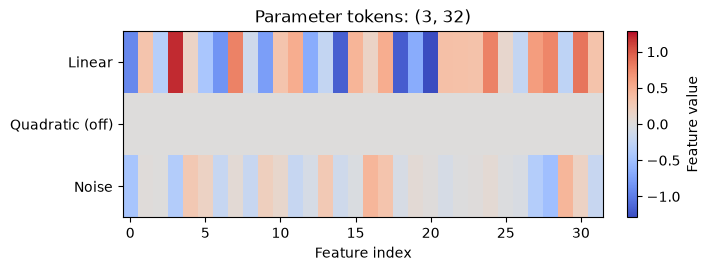

In [11]:
# Parameter tokens from the same initialized tokenizer.
fig, ax = plt.subplots(figsize=(7, 2.6), layout="constrained")
scale = max(float(jnp.max(jnp.abs(parameter_tokens))), 1e-8)
im = ax.imshow(
    parameter_tokens, aspect="auto", cmap="coolwarm", vmin=-scale, vmax=scale
)
ax.set(
    xlabel="Feature index",
    yticks=range(3),
    yticklabels=["Linear", "Quadratic (off)", "Noise"],
    title=f"Parameter tokens: {parameter_tokens.shape}",
)
fig.colorbar(im, ax=ax, label="Feature value")
plt.show()

## 3. Train on simulated observations

`model.loss_fn` returns the mask classification loss and the diffusion training
loss. We add them with equal weights; the diffusion loss is not a parameter NLL.
PRISM handles the diffusion perturbation, attention masks, and prediction target.

In [12]:
# model.loss_fn: SymbolicPaperModel.loss_fn in prism/symbolic/paper/model.py.
# Mask loss: prism/symbolic/paper/autoregressive.py; diffusion loss: prism/nn/diffusion.py.
# This notebook wrapper adds the two returned losses with equal weights.
def loss_fn(model, batch, key):
    losses = model.loss_fn(
        key,
        model_mask=batch["mask"],
        theta=batch["theta"],
        x=batch["y"],
        mask_prior=batch["lambda"],
    )
    return losses.sum(), losses

The update below uses RAdam and keeps an exponential moving average (EMA) of
the weights for inference. `nnx.value_and_grad` computes gradients;
`optimizer.update` applies them. `nnx.jit` compiles the update on its first call.

In [13]:
# train_step is defined here, using Flax NNX gradients and Optax updates.
# optax.radam updates the weights; optax.incremental_update maintains their EMA.
optimizer = nnx.Optimizer(model, optax.radam(5e-4), wrt=nnx.Param)
ema_params = nnx.state(model, nnx.Param)
EMA_DECAY = 0.99


@nnx.jit
def train_step(model, optimizer, ema_params, batch, key):
    (_, losses), grads = nnx.value_and_grad(loss_fn, has_aux=True)(model, batch, key)
    optimizer.update(model, grads)
    ema_params = optax.incremental_update(
        nnx.state(model, nnx.Param), ema_params, step_size=1 - EMA_DECAY
    )
    return ema_params, losses

In [14]:
# Notebook training loop: generate a fresh batch with simulate_batch, then call
# the train_step defined above. This cell does not invoke the CLI training script.
NUM_STEPS = 1000
BATCH_SIZE = 32
key = jax.random.PRNGKey(3)
history = []
model.train()

for step in range(NUM_STEPS):
    key, data_key, loss_key = jax.random.split(key, 3)
    batch = simulate_batch(jax.random.split(data_key, BATCH_SIZE))
    ema_params, losses = train_step(model, optimizer, ema_params, batch, loss_key)
    history.append(np.asarray(losses))
    if (step + 1) % 250 == 0:
        print(f"Step {step + 1}: mask={losses[0]:.3f}, diffusion={losses[1]:.3f}")

assert np.isfinite(history).all()

Step 250: mask=0.421, diffusion=1.298


Step 500: mask=0.323, diffusion=1.691


Step 750: mask=0.332, diffusion=0.960


Step 1000: mask=0.297, diffusion=1.372


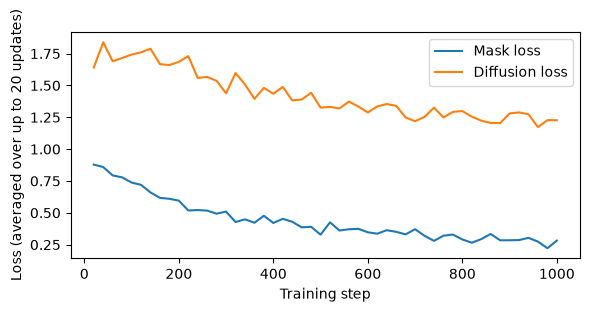

In [15]:
# Notebook visualization: average recorded losses over groups of up to 20 updates.
averaged = np.array([
    np.mean(history[start : start + 20], axis=0) for start in range(0, NUM_STEPS, 20)
])
steps = np.minimum(np.arange(20, NUM_STEPS + 20, 20), NUM_STEPS)
plt.figure(figsize=(6, 3))
plt.plot(steps, averaged[:, 0], label="Mask loss")
plt.plot(steps, averaged[:, 1], label="Diffusion loss")
plt.xlabel("Training step")
plt.ylabel("Loss (averaged over up to 20 updates)")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Save and restore the EMA weights

Save the training state and EMA weights with the existing checkpoint manager,
then restore the EMA weights into a fresh network for inference. This example
uses a temporary directory, removed after restoration. The notebook's
`network_config` reconstructs the model; this is not a complete CLI run bundle.

In [16]:
# CheckpointManager.save and restore_parameters: prism/train/checkpointing.py.
# Flax nnx.state extracts the model and optimizer state for the temporary checkpoint.
import tempfile

from prism.train.checkpointing import CheckpointManager

restored_model = SymbolicPaperModel(network_config, rngs=nnx.Rngs(9))
with tempfile.TemporaryDirectory(prefix="prism-minimal-") as directory:
    manager = CheckpointManager(directory, max_to_keep=1, keep_best=False)
    try:
        manager.save(
            NUM_STEPS,
            params=nnx.state(model, nnx.Param),
            optimizer_state=nnx.state(optimizer),
            params_ema=ema_params,
            loss=float(np.sum(history[-1])),
        )
        manager.wait_until_finished()
        checkpoint = manager.restore_parameters(
            NUM_STEPS, nnx.state(restored_model, nnx.Param)
        )
    finally:
        manager.close()

In [17]:
# Flax NNX applies the checkpoint's EMA weights and switches to evaluation mode.
nnx.update(restored_model, checkpoint["params_ema"])
restored_model.eval()
print(f"Loaded EMA checkpoint at training step {checkpoint['step']}.")

Loaded EMA checkpoint at training step 1000.


## 5. Infer the model structure

Use the restored EMA network on a new observation. From here onward, the plots
show **trained inference results**. The generating mask and parameters are
retained for comparison but are not passed to the network. The supplied lambda
specifies the prior for this observation.

In [18]:
# Use the network restored from the EMA checkpoint above.
# model.sample_mask: SymbolicPaperModel in prism/symbolic/paper/model.py; it delegates
# to the prior-conditioned decoder in prism/symbolic/paper/autoregressive.py.
# sample_masks is a notebook wrapper that repeats this draw with JAX vmap.
posterior_model = restored_model
observation = simulate(jax.random.PRNGKey(5))
NUM_DRAWS = 128


@nnx.jit
def sample_masks(model, y, mask_prior, key):
    return jax.vmap(lambda k: model.sample_mask(k, x=y, mask_prior=mask_prior))(
        jax.random.split(key, NUM_DRAWS)
    )


masks = sample_masks(
    posterior_model, observation["y"], observation["lambda"], jax.random.PRNGKey(6)
)
assert bool(jnp.all(masks[:, :2].any(axis=1) & masks[:, 2]))
print("Generating mask:", observation["mask"], "lambda:", observation["lambda"])

Generating mask: [ True  True  True] lambda: [0.8910189]


### How lambda changes model probabilities

Keep the observation and trained weights fixed, and change only lambda.
The bars compare the prior and posterior over the three possible function models.
The mask decoder uses both its lambda embedding and the prior's conditional
probabilities. Only this tiny model space is enumerated for inspection; normal
sampling does not enumerate every model.

In [19]:
# model.log_prob_mask: SymbolicPaperModel in prism/symbolic/paper/model.py.
# prior.prob: MaskPrior in prism/simulators/mask_prior.py.
# mask_probabilities is a notebook helper that enumerates this tiny model space.
model_masks = jnp.array([[True, False, True], [False, True, True], [True, True, True]])


@nnx.jit
def mask_probabilities(model, y, mask_prior):
    log_probs = jax.vmap(lambda m: model.log_prob_mask(m, x=y, mask_prior=mask_prior))(
        model_masks
    )
    return jnp.exp(log_probs)


lambda_values = jnp.array([[0.1], [0.5], [0.9]])
posterior_probs = jnp.stack([
    mask_probabilities(posterior_model, observation["y"], value)
    for value in lambda_values
])
prior_probs = jax.vmap(
    lambda value: jax.vmap(lambda m: prior.prob(m, value))(model_masks)
)(lambda_values)
np.testing.assert_allclose(posterior_probs.sum(axis=1), 1.0, atol=1e-5)

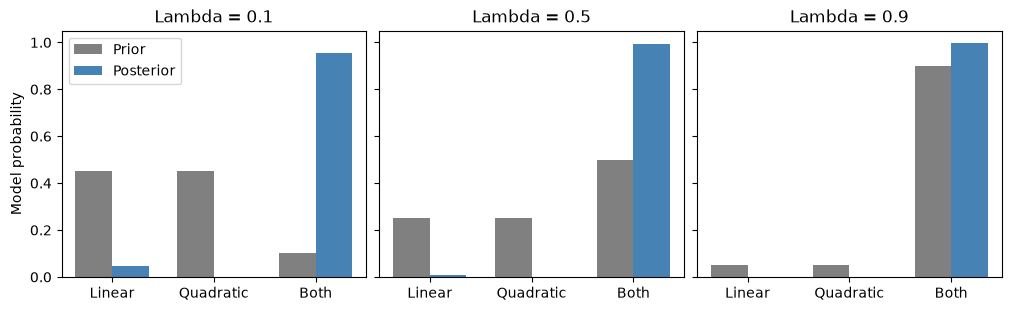

In [20]:
# Notebook visualization: compare prior and posterior probabilities at each lambda.
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True, layout="constrained")
positions = np.arange(3)
for i, ax in enumerate(axes):
    ax.bar(positions - 0.18, prior_probs[i], width=0.36, label="Prior", color="gray")
    ax.bar(
        positions + 0.18,
        posterior_probs[i],
        width=0.36,
        label="Posterior",
        color="steelblue",
    )
    ax.set(
        xticks=positions,
        xticklabels=["Linear", "Quadratic", "Both"],
        ylim=(0, 1.05),
        title=f"Lambda = {float(lambda_values[i, 0]):.1f}",
    )
axes[0].set_ylabel("Model probability")
axes[0].legend()
plt.show()

### Sampled model probabilities

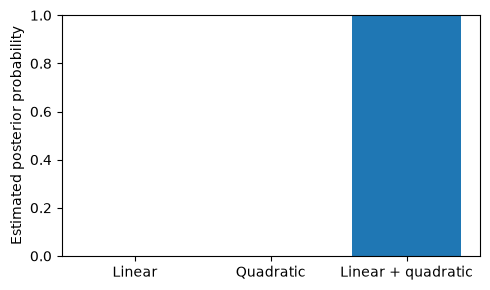

In [21]:
# Notebook calculation: estimate model probabilities by counting sampled masks.
probabilities = jnp.mean(
    jnp.all(masks[:, None, :] == model_masks[None, :, :], axis=-1), axis=0
)
plt.figure(figsize=(5, 3))
plt.bar(["Linear", "Quadratic", "Linear + quadratic"], probabilities)
plt.ylabel("Estimated posterior probability")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Inspect one autoregressive mask draw

The decoder selects bits in order. At each position its probability is conditional
on the bits already selected. These are conditional probabilities, not independent marginals. For this tiny example, compute those conditional probabilities
from the network's joint probabilities and follow the first sampled mask.

Only the two function bits are plotted; the noise bit is always active.

In [22]:
# Notebook diagnostic: derive each conditional bit probability from joint_probs.
# mask_probabilities is defined above; this is not a replacement for the sampler.
joint_probs = mask_probabilities(
    posterior_model, observation["y"], observation["lambda"]
)
chosen_mask = masks[0]
bit_probs = []
for i in range(chosen_mask.size):
    agrees = jnp.all(model_masks[:, :i] == chosen_mask[:i], axis=1)
    prefix_mass = jnp.sum(joint_probs * agrees)
    bit_probs.append(jnp.sum(joint_probs * agrees * model_masks[:, i]) / prefix_mass)

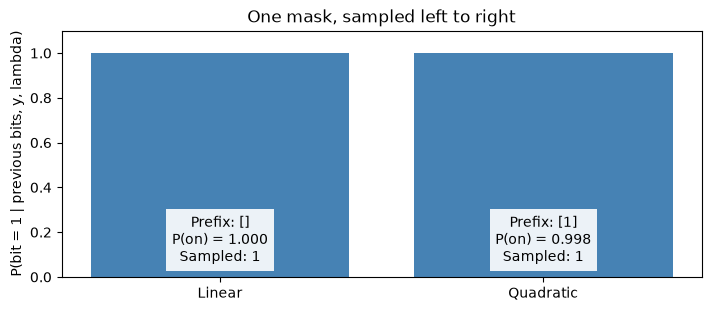

In [23]:
# Notebook visualization: show only the two function bits of one sampled mask.
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.bar(["Linear", "Quadratic"], bit_probs[:2], color="steelblue")
for i, probability in enumerate(bit_probs[:2]):
    prefix = np.asarray(chosen_mask[:i], dtype=int).tolist()
    ax.text(
        i,
        0.05,
        f"Prefix: {prefix}\nP(on) = {float(probability):.3f}\nSampled: {int(chosen_mask[i])}",
        ha="center",
        va="bottom",
        bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"),
    )
ax.set(
    ylim=(0, 1.1),
    ylabel="P(bit = 1 | previous bits, y, lambda)",
    title="One mask, sampled left to right",
)
plt.show()

## 6. Infer parameters for the sampled models

For each mask draw $M_i$, sample $\theta_i\sim q(\theta\mid M_i,y)$.
This gives paired joint posterior draws $(M_i,\theta_i)$.

In [24]:
# model.sample_theta: SymbolicPaperModel in prism/symbolic/paper/model.py; it calls
# EDMSimformer.sample in prism/symbolic/paper/simformer.py.
# sample_parameters is a notebook wrapper that draws parameters for each mask.
@nnx.jit
def sample_parameters(model, y, masks, key):
    keys = jax.random.split(key, masks.shape[0])
    return jax.vmap(
        lambda k, m: model.sample_theta(k, x=y, model_mask=m, num_steps=32)
    )(keys, masks)


thetas = sample_parameters(
    posterior_model, observation["y"], masks, jax.random.PRNGKey(7)
)
assert thetas.shape == (NUM_DRAWS, Simulator.theta_dim)
assert bool(jnp.isfinite(thetas).all())

Convert the unconstrained parameters to natural coefficients using the simulator.
Plot the **effective coefficients** $m_1a$ and $m_2b$: an absent term contributes
exactly zero. The histograms therefore include uncertainty about model structure.

The noise-scale posterior is omitted from the display but retained for predictions.

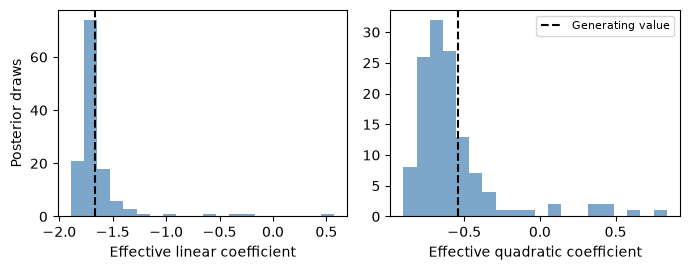

In [25]:
# coefficients is a notebook helper that reads the constructed simulator.
# Parameter transforms: SymbolicExpressionCompartment and SymbolicNoiseCompartment
# in prism/symbolic/simulators/model.py. Histograms include inactive terms as zero.
def coefficients(theta, mask):
    simulator = Simulator.from_theta(theta, model_mask=mask)
    a, b = [component.params_array[0] for component in simulator.model_compartments]
    sigma = simulator.noise_compartments[0].params_array[0]
    return jnp.array([mask[0] * a, mask[1] * b, sigma])


draws = jax.vmap(coefficients)(thetas, masks)
truth = coefficients(observation["theta"], observation["mask"])
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8))
for index, label in enumerate([
    "Effective linear coefficient",
    "Effective quadratic coefficient",
]):
    axes[index].hist(draws[:, index], bins=20, color="steelblue", alpha=0.7)
    axes[index].axvline(
        truth[index], color="black", linestyle="--", label="Generating value"
    )
    axes[index].set_xlabel(label)
axes[0].set_ylabel("Posterior draws")
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Generate posterior predictions

Send each pair $(M_i,\theta_i)$ through the same simulator, adding fresh noise.
The shaded band is the pointwise 5th–95th percentile of these predictions, not
a confidence interval for the estimated mean. A short training run need not
produce a calibrated band.

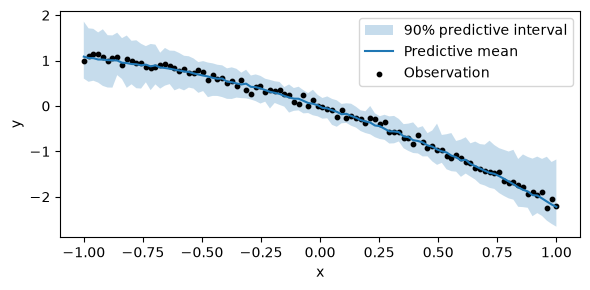

In [26]:
# predict is a notebook wrapper around AdditiveModel.evaluate
# in prism/symbolic/simulators/base.py; a fresh key adds observation noise.
# The remaining lines compute pointwise quantiles and plot the predictions.
def predict(theta, mask, key):
    simulator = Simulator.from_theta(theta, model_mask=mask)
    return simulator.evaluate(grid, rng=key)


predictions = jax.vmap(predict)(
    thetas, masks, jax.random.split(jax.random.PRNGKey(8), NUM_DRAWS)
)
assert predictions.shape == (NUM_DRAWS, len(grid))
assert bool(jnp.isfinite(predictions).all())
lower, upper = np.quantile(predictions, [0.05, 0.95], axis=0)
plt.figure(figsize=(6, 3))
plt.fill_between(grid, lower, upper, alpha=0.25, label="90% predictive interval")
plt.plot(grid, predictions.mean(axis=0), label="Predictive mean")
plt.scatter(
    grid, observation["y"].reshape(-1), s=10, color="black", label="Observation"
)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
# Verify restored inference against an independent copy of the in-memory EMA.
# Both networks use the same sampling keys through the helpers defined above.
reference_model = SymbolicPaperModel(network_config, rngs=nnx.Rngs(4))
nnx.update(reference_model, ema_params)
reference_model.eval()
reference_masks = sample_masks(
    reference_model, observation["y"], observation["lambda"], jax.random.PRNGKey(6)
)
np.testing.assert_array_equal(reference_masks, masks)
reference_thetas = sample_parameters(
    reference_model, observation["y"], reference_masks, jax.random.PRNGKey(7)
)
np.testing.assert_array_equal(reference_thetas, thetas)
print(
    "Restored EMA and in-memory EMA produce exactly the same mask and parameter draws."
)

Restored EMA and in-memory EMA produce exactly the same mask and parameter draws.


For saved training runs, validation, and checkpoint selection, continue with
[the training guide](../../docs/guides/training.md).
For custom function components, see [the symbolic simulator guide](../../docs/guides/symbolic.md).

## 8. Figure 4b: completed reproduction results

These results come from separate GPU experiments with **15 candidate functions,
5 noise types, a fixed mask prior, batch size 128, and best EMA checkpoints**.
They are not produced by the small polynomial training run above.

Each point evaluates 1,000 fresh curves with 500 observations per curve. The
vertical axis is mean prediction RMSE minus the historical noise-floor estimate
`15.80477523803711`; lower is better. The plots show means only.

The compact saved summary below is included so this notebook runs without cluster
access. See [the simulation-efficiency experiment](https://github.com/mackelab/prism/blob/main/experiments/symbolic/simulation_efficiency/README.md)
for the training and evaluation workflow.

In [28]:
# Saved results: baseline/experiment-status-2026-09-13-1034/symbolic-results.json.
# Columns below copy training_datasets, paper_prism, paper_sbmi, and batch128_best.
# Evaluation implementation: experiments/symbolic/simulation_efficiency/evaluate.py.
# This cell displays completed experiments; it does not train or evaluate a model.
import pandas as pd

fig4b_results = pd.DataFrame(
    [
        ("10k", 1.584268682756616, 9.610879898071289, 1.6846885681152344),
        ("25k", 1.6509112189614341, 6.373382568359375, 1.1001911163330078),
        ("50k", 0.9695588748797037, 3.0993194580078125, 0.9717826843261719),
        ("100k", 0.6671239693352534, 2.6385421752929688, 0.7099342346191406),
        ("200k", 0.5131398273070032, 1.8614387512207031, 0.4701423645019531),
        ("500k", 0.2612112356297004, 0.9344310760498047, 0.2513866424560547),
        ("1000k", 0.2119389819702875, 0.9478530883789062, 0.1918478012084961),
    ],
    columns=[
        "Training budget",
        "Published PRISM",
        "Published SBMI",
        "My PRISM (best EMA)",
    ],
)
fig4b_budgets = np.array([
    int(label[:-1]) * 1000 for label in fig4b_results["Training budget"]
])

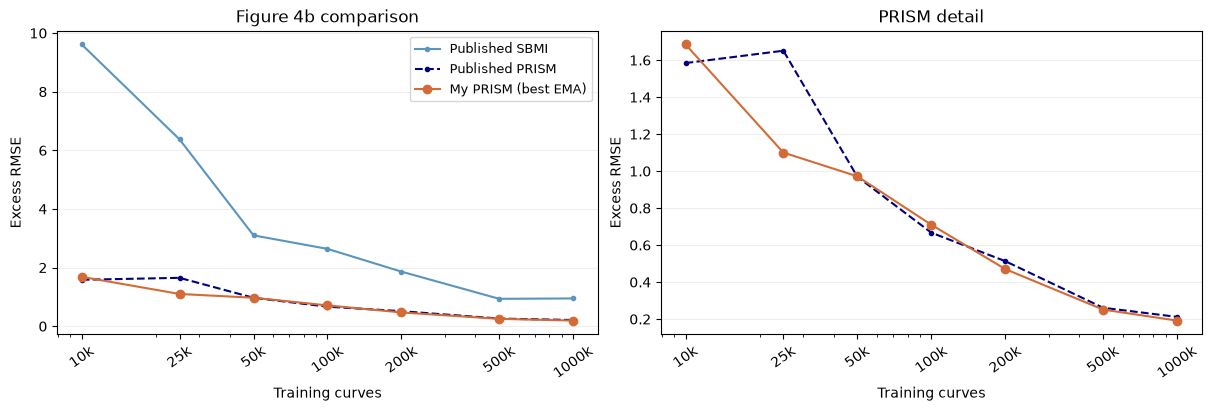

,Published PRISM,Published SBMI,My PRISM (best EMA)
Training budget,,,
10k,1.584,9.611,1.685
25k,1.651,6.373,1.100
50k,0.970,3.099,0.972
100k,0.667,2.639,0.710
200k,0.513,1.861,0.470
500k,0.261,0.934,0.251
1000k,0.212,0.948,0.192


In [29]:
# Show the full Figure 4b comparison and a PRISM close-up.
# Matplotlib plots the saved means; Pandas formats the same values as a table.
from IPython.display import display

series = [
    ("Published SBMI", "#5995bd", ".-"),
    ("Published PRISM", "navy", ".--"),
    ("My PRISM (best EMA)", "#d46b36", "o-"),
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, entries, title in zip(
    axes, [series, series[1:]], ["Figure 4b comparison", "PRISM detail"], strict=True
):
    for label, color, marker in entries:
        ax.plot(fig4b_budgets, fig4b_results[label], marker, color=color, label=label)
    ax.set_xscale("log")
    ax.set_xticks(fig4b_budgets, fig4b_results["Training budget"], rotation=35)
    ax.set(xlabel="Training curves", ylabel="Excess RMSE", title=title)
    ax.grid(axis="y", alpha=0.2)
axes[0].legend(fontsize=9)
plt.show()

display(
    fig4b_results
    .set_index("Training budget")
    .style.format("{:.3f}")
    .set_table_styles([
        {
            "selector": "th, td",
            "props": [
                ("color", "#172b4d !important"),
                ("background-color", "#ffffff !important"),
                ("padding", "8px 12px"),
            ],
        },
        {"selector": "th", "props": [("background-color", "#eaf0f6 !important")]},
    ])
)

The batch128/best-EMA results broadly follow the published PRISM curve and are
below the stored SBMI reference at all seven budgets. Published PRISM values were
digitized from the repository SVG and checked against the paper PDF; SBMI values
come from stored reference results, not a new SBMI training run.

These are single-training-seed results. The 200k, 500k, and 1000k runs used eight
A100 training hours, which does not establish the same compute budget or step
count as the historical H100 runs. The original figure checkpoint identities
remain unverified.

## 9. Symbolic and dMRI: input formats

### How components produce an observation

Symbolic adds function components. dMRI mixes compartment signals using their
fractions. Below, both plots use the existing simulators with fixed example
parameters and no observation noise. The dMRI acquisition is a small synthetic
two-shell example with directions in the XY plane, not a paper dataset.

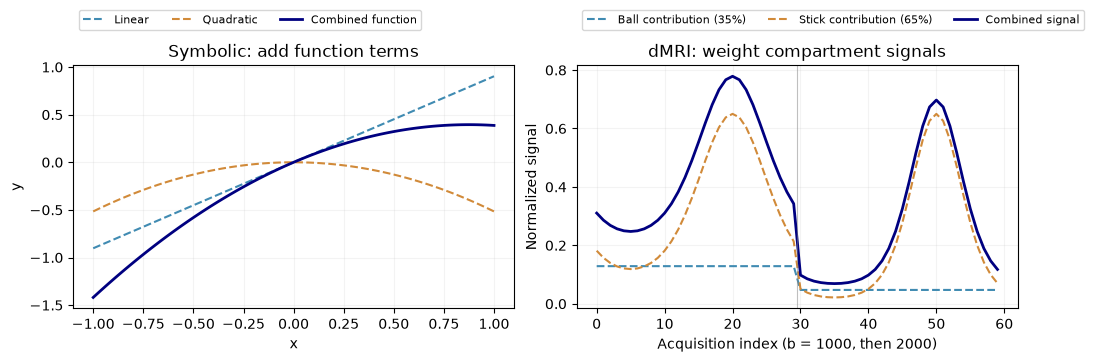

In [30]:
# Existing dMRI components and mixture: prism/dmri/simulators/models.py
# and prism/dmri/simulators/local_signal_models/{ball,stick}.py.
# Acquisition container: prism/dmri/simulators/acquisition_scheme.py.
from prism.dmri.simulators.acquisition_scheme import acquisition_scheme
from prism.dmri.simulators.local_signal_models import Ball, Stick
from prism.dmri.simulators.models import BallStick

# Use the same polynomial simulator and 100-point grid as above.
poly_demo = Simulator.from_theta(
    jnp.array([0.6, -0.7, -0.2]), model_mask=jnp.array([True, True, True])
)
poly_parts = jnp.stack([c.evaluate(grid) for c in poly_demo.model_compartments])
poly_signal = poly_demo.evaluate(grid)
np.testing.assert_allclose(poly_parts.sum(axis=0), poly_signal, atol=1e-6)

# Repeat 30 directions at two b-values, giving 60 acquisitions.
angles = jnp.linspace(0.0, jnp.pi, 30, endpoint=False)
directions = jnp.stack(
    (jnp.cos(angles), jnp.sin(angles), jnp.zeros_like(angles)), axis=1
)
dmri_acq = acquisition_scheme(
    bvals=jnp.repeat(jnp.array([1000.0, 2000.0]), 30),
    bvecs=jnp.tile(directions, (2, 1)),
)
dmri_demo = BallStick(
    model_fractions=jnp.array([0.35, 0.65]),
    model_compartments=[
        Ball(lam=0.001),
        Stick(mu=jnp.array([jnp.pi / 2, jnp.pi / 6]), lam_par=0.0017),
    ],
    noise_compartments=[],
    model_mask=jnp.array([True, True]),
)
# Weight existing component signals; the actual mixture uses MultiCompartment.signal.
dmri_parts = jnp.stack([
    fraction * component.signal(dmri_acq)
    for fraction, component in zip(
        dmri_demo.model_fractions, dmri_demo.model_compartments, strict=True
    )
])
dmri_signal = dmri_demo.signal(dmri_acq)
np.testing.assert_allclose(dmri_parts.sum(axis=0), dmri_signal, atol=1e-6)
np.testing.assert_allclose(jnp.linalg.norm(dmri_acq.bvecs, axis=1), 1.0, atol=1e-6)
assert bool(jnp.isfinite(dmri_signal).all())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for values, label, color in zip(
    poly_parts, ["Linear", "Quadratic"], ["#408bb2", "#d18a39"], strict=True
):
    axes[0].plot(grid, values, "--", color=color, label=label)
axes[0].plot(grid, poly_signal, color="navy", lw=2, label="Combined function")
axes[0].set(title="Symbolic: add function terms", xlabel="x", ylabel="y")
for values, label, color in zip(
    dmri_parts,
    ["Ball contribution (35%)", "Stick contribution (65%)"],
    ["#408bb2", "#d18a39"],
    strict=True,
):
    axes[1].plot(values, "--", color=color, label=label)
axes[1].plot(dmri_signal, color="navy", lw=2, label="Combined signal")
axes[1].axvline(29.5, color="gray", lw=0.8, alpha=0.5)
axes[1].set(
    title="dMRI: weight compartment signals",
    xlabel="Acquisition index (b = 1000, then 2000)",
    ylabel="Normalized signal",
)
for ax in axes:
    ax.legend(fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.12), ncol=3)
    ax.grid(alpha=0.15)
plt.show()

### What the observation encoder receives

**Symbolic:** the same 100 y-values become ten blocks of ten. Their order locates
them on the fixed x-grid.

**dMRI:** each of the 60 signal values comes with a b-value and a gradient
direction. These are supplied as a signal array and an acquisition object.
Each measurement produces one observation token after feature encoding.
The dMRI panels below show raw inputs with separate color scales, not hidden features.

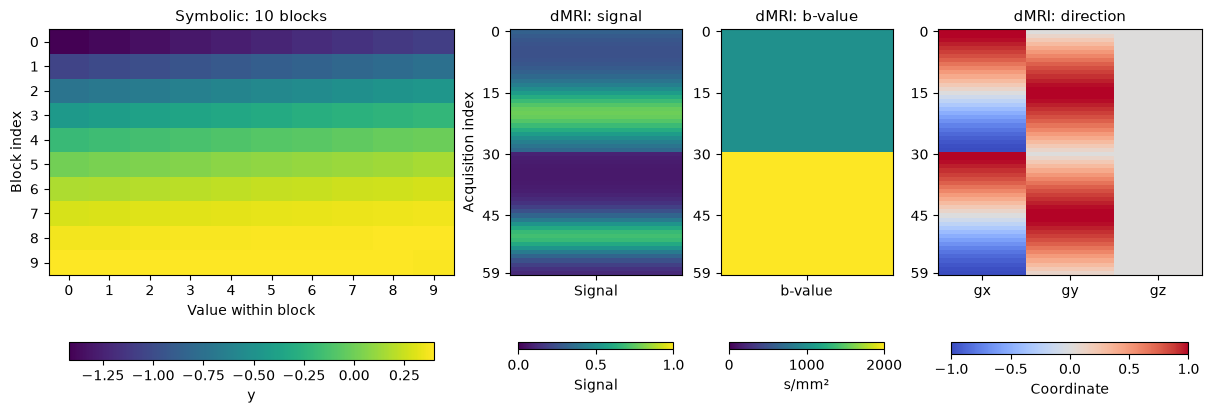

In [31]:
# Symbolic encoder: prism/symbolic/paper/embedding.py.
# dMRI encoder: BvalBvecSignalEmbeddingNet in prism/dmri/nn/embedding.py.
# Display their observation inputs; no new network is trained or evaluated here.
fig, axes = plt.subplots(
    1, 4, figsize=(12, 4), width_ratios=[2.0, 0.85, 0.85, 1.3], layout="constrained"
)
input_panels = [
    (poly_signal.reshape(10, 10), "Symbolic: 10 blocks", "y", "viridis", None, None),
    (dmri_signal[:, None], "dMRI: signal", "Signal", "viridis", 0, 1),
    (dmri_acq.bvals[:, None], "dMRI: b-value", "s/mm²", "viridis", 0, 2000),
    (dmri_acq.bvecs, "dMRI: direction", "Coordinate", "coolwarm", -1, 1),
]
for ax, (values, title, units, cmap, low, high) in zip(axes, input_panels, strict=True):
    im = ax.imshow(values, aspect="auto", cmap=cmap, vmin=low, vmax=high)
    ax.set_title(title, fontsize=11)
    fig.colorbar(im, ax=ax, orientation="horizontal", pad=0.08, label=units, shrink=0.9)
axes[0].set(
    xlabel="Value within block",
    ylabel="Block index",
    xticks=range(10),
    yticks=range(10),
)
axes[1].set(
    ylabel="Acquisition index",
    xticks=[0],
    xticklabels=["Signal"],
    yticks=[0, 15, 30, 45, 59],
)
axes[2].set(xticks=[0], xticklabels=["b-value"], yticks=[0, 15, 30, 45, 59])
axes[3].set(
    xticks=[0, 1, 2], xticklabels=["gx", "gy", "gz"], yticks=[0, 15, 30, 45, 59]
)
plt.show()

Both encoders feed an autoregressive mask decoder and a diffusion parameter
decoder. Their tokenizers reflect the simulator: symbolic function parameters
versus dMRI compartment parameters, mixture fractions, and optional shared parameters.
The observation encoders and tokenizers differ, so their checkpoints are not interchangeable.

Source: `prism/symbolic/paper/embedding.py`, `prism/dmri/nn/embedding.py`,
`prism/symbolic/paper/tokenizer.py`, and `prism/dmri/nn/tokenizer.py`.